# Lab 04: The Scaling Relation That Depends on How You Fit It

**ASTR 457, Fall 2026, posted Thu Sep 24, due Wed Sep 30 by Noon (fork → PR, as always)**

**Extra credit, +5 points on this lab:** if you attended Charlotte Ward's Sep 22 Astronomy Colloquium, turn in at least a page of notes including two questions you had, as a text file in your `submissions/<netid>/` folder, by Noon Tue Sep 29.

*Why this lab: every scaling relation you will ever use ($M_{\rm BH}$–$\sigma$, Tully–Fisher, the mass–metallicity relation, the SN Ia standardization) was fit by someone who chose a regression method, and the choice changes the published slope. Knowing when ordinary least squares lies, by how much, and what to do instead is how you read those papers, and how you referee them.*

Every one of you has your own dataset: `data/<your netid>.csv`, a sample of dwarf
galaxies hosting active galactic nuclei, selected by their optical variability in the
style of Ward et al. (2022, arXiv:2110.13098). Dwarf-galaxy AGN are one of the few
windows we have on black holes in the $10^5$–$10^7\,M_\odot$ range, where the seeds of
supermassive black holes hide. Columns:

- `logMstar`, `err_logMstar`: $x = \log_{10}(M_*/M_\odot)$, the host stellar mass from
  SED fitting, and its $1\sigma$ uncertainty (0.2–0.4 dex; dwarf-galaxy photometry is hard),
- `logMBH`, `err_logMBH`: $y = \log_{10}(M_{\rm BH}/M_\odot)$, the virial black-hole
  mass from broad-line spectroscopy, and its $1\sigma$ uncertainty.

The relation you are after is

$$y = \alpha\,(x - 9.5) + \beta + \text{intrinsic scatter } \sigma_{\rm int},$$

pivoted at $M_* = 10^{9.5} M_\odot$ so $\alpha$ and $\beta$ don't fight each other. **Both
variables have measurement error, and the relation has real astrophysical scatter on top.**
I know your true $\alpha$, $\beta$, and $\sigma_{\rm int}$. You don't, your classmates'
values are different from yours, and so are your sample sizes.

**How this is graded.** Not on whether your code runs, but on whether your answers are
*right* and your uncertainties are *honest*. Part of your grade comes from how close your
reported $\alpha$ and $\beta$ are to your truth **in units of your own reported
uncertainty**. Tiny error bars you can't back up lose points; padded ones lose points too.
Calibration is the skill. The floor under "padded": your reported $\sigma_\alpha$ may not
exceed **3× the curvature uncertainty of your own generative fit** from Part 2 (if your
Hessian turns out singular, quote a profile-likelihood width instead and say so). Bigger
than that is not caution, since it's an estimator you should have discarded.

**AI policy reminder.** Use whatever tools you like, including AI assistants, and document
it in Part 4. You may be selected to defend this lab in person. Welcome to doing research.

## Part 1: The fit everyone does first (15%)

Load your sample and plot it with error bars **on both axes**. Then fit the relation the
way most papers still do: **ordinary least squares** on $y$ vs $(x - 9.5)$, every point
weighted equally, errors ignored. Build the design matrix and solve the normal equations
yourself (lecture machinery, or `np.polyfit` if you must, but know what it's doing). Report
$\hat\alpha \pm \sigma$ using the standard OLS variance estimate, $s^2 (A^{\mathsf T}A)^{-1}$
with $s^2 = \mathrm{RSS}/(N-2)$ (residual-scaled; the errors play no role yet, on purpose).

Then answer, in a few sentences: which of OLS's assumptions does *your* dataset violate?
For the slope specifically, which way does the bias from the $x$-errors pull, and what
controls its size? (We named it in lecture on Sep 24. The effect is *supposed*
to be there; understanding exactly why, on your own data, is the point of this lab.)

alpha = 1.121 ± 0.184
beta  = 6.423 ± 0.144
alpha = 1.121 ± 0.184
beta  = 6.423 ± 0.144


/var/folders/79/f40vsy253hj8h9gqrb233j580000gn/T/ipykernel_34882/3658655313.py:10: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k." (-> color='k'). The keyword argument will take precedence.
  plt.errorbar(x, y, yerr=ey, xerr=ex, fmt='k.', capsize=2, color ='blue')


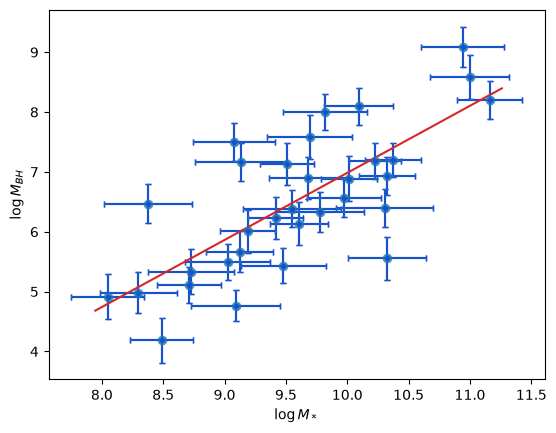

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Part 1: your work here
d = np.genfromtxt('cmewing2-2.csv', delimiter=',', names=True, encoding='utf-8-sig')
x, ex, y, ey = d['logMstar'], d['err_logMstar'], d['logMBH'], d['err_logMBH']
N = len(x)

plt.errorbar(x, y, yerr=ey, xerr=ex, fmt='k.', capsize=2, color ='blue')
plt.xlabel(r'$\log M_*$'); plt.ylabel(r'$\log M_{BH}$')

A = np.column_stack([x - 9.5, np.ones(N)])          # design matrix
theta = np.linalg.solve(A.T @ A, A.T @ y)           # normal equations
alpha, beta = theta
res = y - A @ theta
s2 = res @ res / (N - 2)
cov = s2 * np.linalg.inv(A.T @ A)
print(f"alpha = {alpha:.3f} ± {np.sqrt(cov[0,0]):.3f}")
print(f"beta  = {beta:.3f} ± {np.sqrt(cov[1,1]):.3f}")


X = sm.add_constant(x - 9.5)        # columns: [intercept, slope term]
fit = sm.OLS(y, X).fit()
beta, alpha = fit.params            # note the order: intercept first
sig_beta, sig_alpha = fit.bse
print(f"alpha = {alpha:.3f} ± {sig_alpha:.3f}")
print(f"beta  = {beta:.3f} ± {sig_beta:.3f}")

xx = np.linspace(x.min() - 0.1, x.max() + 0.1, 100)
plt.errorbar(x, y, yerr=ey, xerr=ex, fmt='o', color='tab:blue', ecolor='tab:blue', capsize=2, alpha=0.7)
plt.plot(xx, alpha * (xx - 9.5) + beta, color='tab:red')

**ANSWER (a few sentences):**

*OLS ignores the errors and weights every point equally.*

## Part 2: Estimators you can defend (40%)

Now fit the relation **three more ways** and compare:

1. **Weighted least squares** using the $y$-errors only:
   $\hat{\theta} = (A^{\mathsf T}\Sigma^{-1}A)^{-1}A^{\mathsf T}\Sigma^{-1}y$ with
   $\Sigma = \mathrm{diag}(\sigma_{y,i}^2)$, parameter covariance
   $(A^{\mathsf T}\Sigma^{-1}A)^{-1}$. Does weighting fix the Part 1 bias? Why or why not?

2. **Orthogonal distance regression** (`scipy.odr`, which warns that it is deprecated on
   import; that is fine in the course environment), which knows about the $x$-errors.
   Read what it minimizes before you run it. What does ODR assume about scatter
   *perpendicular to the relation*, and is that assumption true here?

3. **The generative model, honestly.** Write down where each data point comes from:
   the true stellar masses are drawn from the population,
   $x_i^{\rm true} \sim \mathcal{N}(\mu, \sigma_{\rm pop}^2)$; the relation plus intrinsic scatter
   makes the true BH mass; and your measurement errors corrupt both. Marginalizing over
   the (unobservable) true masses makes each observed pair $(x_i, y_i)$ a **bivariate
   Gaussian**:

   $$\begin{pmatrix} x_i \\ y_i \end{pmatrix} \sim \mathcal{N}\!\left[
   \begin{pmatrix} \mu \\ \alpha(\mu - 9.5) + \beta \end{pmatrix},\;
   \begin{pmatrix} \sigma_{\rm pop}^2 + \sigma_{x,i}^2 & \alpha\,\sigma_{\rm pop}^2 \\
   \alpha\,\sigma_{\rm pop}^2 & \alpha^2\sigma_{\rm pop}^2 + \sigma_{\rm int}^2 + \sigma_{y,i}^2 \end{pmatrix}
   \right]$$

   (Convince yourself of the three variance entries before you code; the off-diagonal
   covariance is what removes the attenuation bias. This is the Gaussian core of Kelly 2007, the paper behind
   every modern `linmix`-style fit.) Maximize the summed log-likelihood over all five
   parameters $(\alpha, \beta, \sigma_{\rm int}, \mu, \sigma_{\rm pop})$, and get uncertainties from
   the curvature of the log-likelihood at its peak (the observed information), and say so.

Make **one plot with all four fitted lines overplotted** on your data. They will not agree.
Explain, estimator by estimator, *why* each lands where it does, and which ingredient of the
data each one ignores.

Commit to a **final answer**: one $\alpha \pm \sigma$, $\beta \pm \sigma$, and
$\sigma_{\rm int} \pm \sigma$ you'd put in a paper, and justify the choice. Remember the
3× rule from the header.

Optimization success: True
Negative log-likelihood: 74.18743432427357
Parameters: [ 1.3748204   6.38439372 -0.58800371  9.59169954 -0.34042964]
Hessian eigenvalues: [ 19.37916065  45.27845699  60.74792413  68.79072133 103.52215493]
alpha = 1.375 ± 0.215
beta = 6.384 ± 0.138
sigma_int = 0.555 ± 0.139
mu = 9.592 ± 0.136
sigma_pop = 0.711 ± 0.104


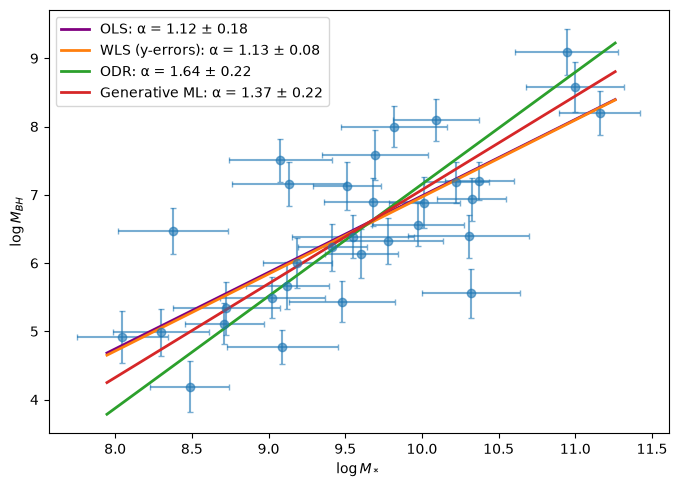

In [33]:
# Part 2: your work here
from scipy.optimize import minimize
from scipy import odr

# 1. WLS, y-errors only
Si = np.diag(1/ey**2)
C = np.linalg.inv(A.T @ Si @ A)
a_w, b_w = C @ A.T @ Si @ y
sd_w = np.sqrt(np.diag(C))

# 2. ODR
model = odr.Model(lambda p, xx: p[0]*(xx - 9.5) + p[1])
out = odr.ODR(odr.RealData(x, y, sx=ex, sy=ey), model, beta0=[1., 6.4]).run()
a_o, b_o = out.beta; sd_o = out.sd_beta

# 3. Generative model (params: alpha, beta, ln s_int, mu, ln s_pop)
def nll(p, x, y, ex, ey, fix_si0=False):
    a, b, lsi, mu, lsp = p

    if fix_si0:
        lsi = -20

    sp2 = np.exp(2 * lsp)
    si2 = np.exp(2 * lsi)

    vx = sp2 + ex**2
    vy = a**2 * sp2 + si2 + ey**2
    cxy = a * sp2

    det = np.maximum(vx * vy - cxy**2, 1e-12)

    dx = x - mu
    dy = y - (a * (mu - 9.5) + b)

    q = (vy * dx**2 - 2 * cxy * dx * dy + vx * dy**2) / det

    return 0.5 * np.sum(
        q + np.log(det) + 2 * np.log(2 * np.pi)
    )

best = None
rng = np.random.default_rng(0)
args = (x, y, ex, ey)

for _ in range(40):
    x0 = [
        rng.uniform(.5, 2),
        rng.uniform(5.5, 7),
        np.log(rng.uniform(.2, 1)),
        x.mean() + rng.normal(0, .3),
        np.log(x.std() * rng.uniform(.6, 1.2))
    ]

    r = minimize(
        nll, x0,
        args=args,
        method='Nelder-Mead',
        options={
            'maxiter': 20000,
            'xatol': 1e-10,
            'fatol': 1e-10
        }
    )

    r = minimize(nll, r.x, args=args, method='BFGS')

    if best is None or r.fun < best.fun:
        best = r

print("Optimization success:", best.success)
print("Negative log-likelihood:", best.fun)
print("Parameters:", best.x)

# uncertainties: Hessian in natural parameters (alpha, beta, s_int, mu, s_pop)
q = np.array([best.x[0], best.x[1], np.exp(best.x[2]), best.x[3], np.exp(best.x[4])])
def nll_nat(q):
    return nll(
        [q[0], q[1], np.log(abs(q[2])), q[3], np.log(abs(q[4]))],
        x, y, ex, ey
    )

# numerical Hessian of -lnL (observed information) by central finite differences
n = len(q)
h = 1e-4 * np.maximum(1, np.abs(q))
H = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        ei = np.zeros(n); ej = np.zeros(n)
        ei[i], ej[j] = h[i], h[j]
        H[i, j] = (nll_nat(q + ei + ej) - nll_nat(q + ei - ej)
                   - nll_nat(q - ei + ej) + nll_nat(q - ei - ej)) / (4 * h[i] * h[j])

print("Hessian eigenvalues:", np.linalg.eigvalsh(H))   # all > 0 means a proper maximum, not singular
cov = np.linalg.inv(H)                                 # parameter covariance
sd = np.sqrt(np.diag(cov))                             # 1-sigma uncertainties

names = ['alpha', 'beta', 'sigma_int', 'mu', 'sigma_pop']
for nm, v, s in zip(names, q, sd):
    print(f"{nm} = {v:.3f} ± {s:.3f}")
    
fits = [
    ('OLS',            alpha,  beta,  sig_alpha),
    ('WLS (y-errors)', a_w,    b_w,   sd_w[0]),
    ('ODR',            a_o,    b_o,   sd_o[0]),
    ('Generative ML',  q[0],   q[1],  sd[0]),
]
colors = ['purple', 'tab:orange', 'tab:green', 'tab:red']

xx = np.linspace(x.min() - 0.1, x.max() + 0.1, 100)
plt.figure(figsize=(8, 5.5))
plt.errorbar(x, y, yerr=ey, xerr=ex, fmt='o', color='tab:blue', ecolor='tab:blue', capsize=2, alpha=0.6)
for (name, a, b, s), c in zip(fits, colors):
    plt.plot(xx, a * (xx - 9.5) + b, color=c, lw=2, label=f'{name}: α = {a:.2f} ± {s:.2f}')
plt.xlabel(r'$\log M_*$'); plt.ylabel(r'$\log M_{BH}$')
plt.legend()
plt.show()

**FINAL ANSWER:** $\alpha = $ ___ $\pm$ ___ , $\beta = $ ___ $\pm$ ___ , $\sigma_{\rm int} = $ ___ $\pm$ ___ dex

**Justification and uncertainty method (a short paragraph):**

*I beleive that the generative-model maximum-likelihood fit is the best, because it takes in account intrinsic scatter, measurements errors on both axes and the population of true stellar masses. ODR looks more right, but it doesn't take in account the intrinsic scatter so it overcorrects the slope. OLS only accounts for the x error bars and WLS only accounts for the y error bars which underestimated the slope. Thats why the generative model is better because it takes account of all of those things the other models do not. *

## Part 3: The verification plan, written first and then executed (35%)

**Before you run anything below, write the plan** (3a). A verification plan you invent
after seeing the results is a rationalization.

**3a. The plan.** List the checks you will run to decide whether to trust your Part 2
numbers. At minimum, address:

1. **Closure**: simulate a dataset with a truth *you* choose (the generative recipe in
   Part 2 tells you exactly how) and confirm your fit recovers it.
2. **Bias and efficiency**: Monte Carlo all four estimators on many simulated datasets at
   plausible parameters. Plot each estimator's bias and variance for $\alpha$. This is
   *the* figure of this lab.
3. **Coverage**: across your simulations, do your 68% intervals contain the truth 68% of
   the time, for all three reported parameters?
4. **Sensitivity**: what happens to $\hat\alpha$ if the catalog $x$-errors are wrong by
   ±50% (generate correctly, fit with the mis-stated errors)? If the true population isn't Gaussian (try drawing $x^{\rm true}$ from a uniform
   distribution with the same mean and variance instead)? If you had assumed $\sigma_{\rm int} = 0$?

For **each** check, state *in advance* what failure would look like. A check that cannot
fail is not a check.

**3b. The execution.** Run the plan. Report what each check found, including anything that
failed or surprised you. A failed check honestly reported and diagnosed is worth more than
a wall of green checkmarks.

**VERIFICATION PLAN (write this before running 3b):**

*Closure: simulate one very large dataset (N = 4000) and fit it. Failure: any of the five parameters off from truth by more than a few of its own error bars.
Bias and efficiency: run 500 simulations at each of several true α values (0.5, 1.0, 1.37, 2.0), fit with all four estimators, and plot bias and standard deviation of α̂. Failure for the ML fit: a bias that is significant against its Monte Carlo error (std/√n), or an error bar clearly worse than the others without a bias advantage to pay for it.
Coverage: run 1500 simulations at the truth and count how often each 1σ interval contains the truth. Failure: a fraction outside 68% ± about 2.5% (the Monte Carlo error is about 1.2%). Also check that the std of (estimate − truth)/σ is near 1.
Sensitivity: fit with x-errors scaled by 0.5 and 1.5 while generating with the true errors, with a uniform x_true (same mean and variance), and with σ_int fixed at 0. Failure: a shift in α̂ larger than its own 1σ uncertainty (about 0.2).*

In [41]:
# Part 3b: execute the plan here

def hess_sd(q, x, y, ex, ey):
    # q = [alpha, beta, sigma_int, mu, sigma_pop]
    q = np.asarray(q, dtype=float)

    def objective(z):
        if z[2] <= 0 or z[4] <= 0:
            return np.nan

        p = [
            z[0], z[1],
            np.log(z[2]), z[3],
            np.log(z[4])
        ]
        return nll(p, x, y, ex, ey)

    n = len(q)
    h = 1e-4 * np.maximum(1.0, np.abs(q))
    H = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            ei = np.zeros(n)
            ej = np.zeros(n)
            ei[i] = h[i]
            ej[j] = h[j]

            vals = [
                objective(q + ei + ej),
                objective(q + ei - ej),
                objective(q - ei + ej),
                objective(q - ei - ej)
            ]

            if not np.all(np.isfinite(vals)):
                return np.full(n, np.nan)

            H[i, j] = (
                vals[0] - vals[1] - vals[2] + vals[3]
            ) / (4 * h[i] * h[j])

    H = (H + H.T) / 2

    if not np.all(np.isfinite(H)):
        return np.full(n, np.nan)

    try:
        eigenvalues = np.linalg.eigvalsh(H)

        if np.any(eigenvalues <= 0):
            return np.full(n, np.nan)

        cov = np.linalg.inv(H)
        variances = np.diag(cov)

        if np.any(variances <= 0) or not np.all(np.isfinite(variances)):
            return np.full(n, np.nan)

        return np.sqrt(variances)

    except np.linalg.LinAlgError:
        return np.full(n, np.nan)
def simulate(rng, T, ex, ey, uniform=False):
    n = len(ex)
    if uniform:
        h = T['sp'] * np.sqrt(3)
        xt = rng.uniform(T['mu'] - h, T['mu'] + h, n)
    else:
        xt = rng.normal(T['mu'], T['sp'], n)
    yt = T['a'] * (xt - 9.5) + T['b'] + rng.normal(0, T['si'], n)
    return xt + rng.normal(0, ex), yt + rng.normal(0, ey)

def fit_ml(x, y, ex, ey, fix_si0=False):
    # same nll as before, with fix_si0 option; multi-start BFGS from OLS-based guesses
    o = np.polyfit(x - 9.5, y, 1)
    best = None
    for fa, si in [(1.2, .5), (1., .3), (1.5, .8)]:
        x0 = [o[0]*fa, o[1], np.log(si), x.mean(), np.log(max(x.std(), .1)*.9)]
        r = minimize(nll, x0, args=(x, y, ex, ey, fix_si0), method='BFGS')
        if best is None or r.fun < best.fun: best = r
    p = best.x
    return np.array([p[0], p[1], np.exp(p[2]), p[3], np.exp(p[4])])

T = dict(a=1.37, b=6.38, si=0.56, mu=9.59, sp=0.71)
rng = np.random.default_rng(1)

# coverage: hess_sd is your finite-difference Hessian function from Part 2
hits = []
for _ in range(1500):
    xs, ys = simulate(rng, T, ex, ey)
    q = fit_ml(xs, ys, ex, ey); sd = hess_sd(q, xs, ys, ex, ey)
    hits.append(np.abs(q[:3] - [T['a'], T['b'], T['si']]) < sd[:3])
print(np.mean(hits, axis=0))          # want ~0.68 for each

# sensitivity: generate with true errors, fit with mis-stated ones
est = [fit_ml(*simulate(rng, T, ex, ey), ex * 1.5, ey)[0] for _ in range(600)]
print(np.mean(est) - T['a'])

def nll(p, x, y, ex, ey, fix_si0=False):
    a, b, log_si, mu, log_sp = p

    if fix_si0:
        log_si = -20

    sp2 = np.exp(2 * log_sp)
    si2 = np.exp(2 * log_si)

    vx = sp2 + ex**2
    vy = a**2 * sp2 + si2 + ey**2
    cxy = a * sp2

    det = np.maximum(vx * vy - cxy**2, 1e-12)

    dx = x - mu
    dy = y - (a * (mu - 9.5) + b)

    q = (
        vy * dx**2
        - 2 * cxy * dx * dy
        + vx * dy**2
    ) / det

    return 0.5 * np.sum(
        q + np.log(det) + 2 * np.log(2 * np.pi)
    )

import inspect
print(inspect.signature(nll))

[0.65466667 0.66533333 0.652     ]
0.36399685772068313
(p, x, y, ex, ey, fix_si0=False)


## Part 4: AI-use appendix (10%)

**AI use**: which tools did you use (Copilot, Claude, ChatGPT, none, ...), for what,
what did they get wrong, and how did you catch it? Honesty is graded; "I didn't use any"
is fine if true.

**AI-USE APPENDIX:**

*I used ChatBGT*